# импорты

In [ ]:
!pip install -q pgmpy

In [ ]:
import pandas as pd
import numpy as np
from itertools import product

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from pgmpy.models import DiscreteBayesianNetwork

In [ ]:
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

In [ ]:
import networkx as nx

In [ ]:
from pgmpy.inference import VariableElimination

#анализ данных

In [ ]:
url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"
df = pd.read_csv(url)

df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [ ]:
df.shape

(344, 8)

In [ ]:
df.dtypes

,0
species,object
island,object
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,object
year,int64


In [ ]:
df.isnull().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [ ]:
df.nunique()

,0
species,3
island,3
bill_length_mm,164
bill_depth_mm,80
flipper_length_mm,55
body_mass_g,94
sex,2
year,3


In [ ]:
df.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


In [ ]:
features = [
    'species',
    'island',
    'bill_length_mm',
    'flipper_length_mm',
    'body_mass_g',
    'sex'
]

In [ ]:
data = df[features].copy()
data = data.dropna()
data = data.reset_index(drop=True)

len(data)

333

In [ ]:
data.isnull().sum()

,0
species,0
island,0
bill_length_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


#дискретизация

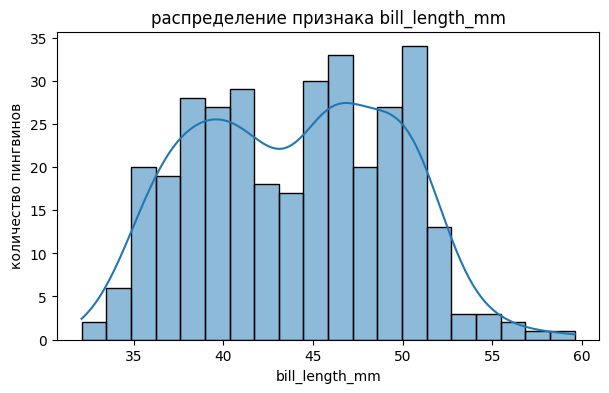

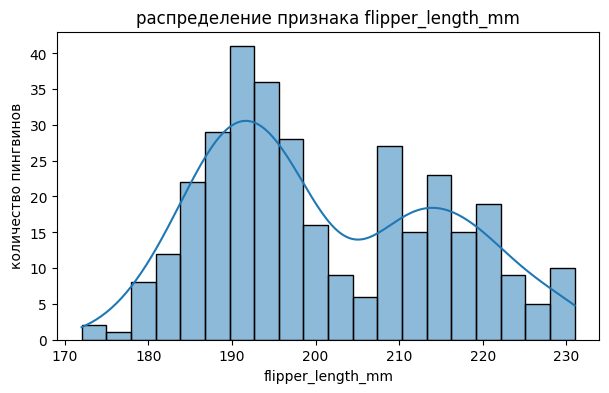

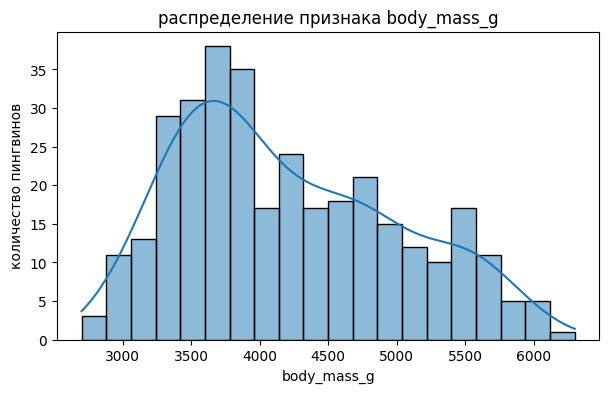

In [ ]:
numeric_features = [
    'bill_length_mm',
    'flipper_length_mm',
    'body_mass_g'
]

for column in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data[column], bins=20, kde=True)
    plt.title(f'распределение признака {column}')
    plt.xlabel(column)
    plt.ylabel('количество пингвинов')
    plt.show()

квантильная тк небольшая выборка, равное кол-во поможет избежать сликом редких состояний, понятные названия для категорий

In [ ]:
for column in numeric_features:
    print(f"\n{column}")
    print(data[column].quantile([0, 1/3, 2/3, 1]))


bill_length_mm
0.000000    32.100000
0.333333    40.866667
0.666667    46.800000
1.000000    59.600000
Name: bill_length_mm, dtype: float64

flipper_length_mm
0.000000    172.0
0.333333    192.0
0.666667    209.0
1.000000    231.0
Name: flipper_length_mm, dtype: float64

body_mass_g
0.000000    2700.0
0.333333    3700.0
0.666667    4550.0
1.000000    6300.0
Name: body_mass_g, dtype: float64


In [ ]:
discrete_data = data.copy()
labels = ['low', 'medium', 'high']

for column in numeric_features:
    discrete_data[column] = pd.qcut(
        discrete_data[column],
        q=3,
        labels=labels
    )

display(discrete_data.head())

,species,island,bill_length_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,low,low,medium,male
1,Adelie,Torgersen,low,low,medium,female
2,Adelie,Torgersen,low,medium,low,female
3,Adelie,Torgersen,low,medium,low,female
4,Adelie,Torgersen,low,low,low,male


In [ ]:
for column in numeric_features:
    print(discrete_data[column].value_counts(sort=False))
    print()

bill_length_mm
low       111
medium    113
high      109
Name: count, dtype: int64

flipper_length_mm
low       115
medium    108
high      110
Name: count, dtype: int64

body_mass_g
low       113
medium    110
high      110
Name: count, dtype: int64



In [ ]:
for column in ['species', 'island', 'sex']:
    print(discrete_data[column].value_counts())
    print()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

sex
male      168
female    165
Name: count, dtype: int64



# граф

In [ ]:
model = DiscreteBayesianNetwork([
    ('island', 'species'),
    ('species', 'bill_length_mm'),
    ('species', 'flipper_length_mm'),
    ('species', 'sex'),
    ('species', 'body_mass_g'),
    ('sex', 'body_mass_g')
])

In [ ]:
print("кол-во вершин:", len(model.nodes()))
print("кол-во рёбер:", len(model.edges()))

print("граф DAG:",
      nx.is_directed_acyclic_graph(model))

кол-во вершин: 6
кол-во рёбер: 6
граф DAG: True


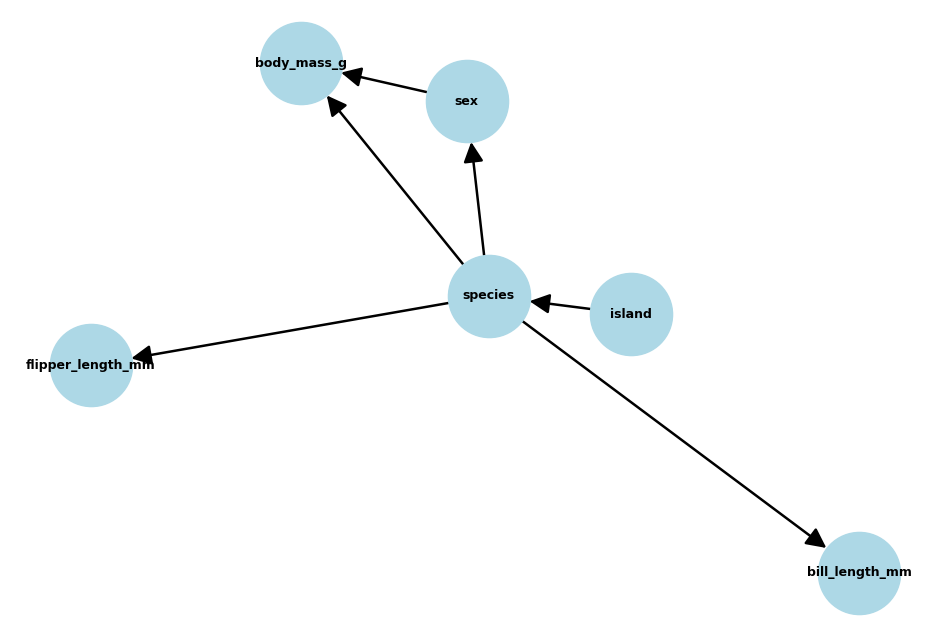

In [ ]:
graph = nx.DiGraph()

graph.add_nodes_from(model.nodes())
graph.add_edges_from(model.edges())

pos = nx.spring_layout(graph, seed=42)

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(graph, seed=42)

nx.draw_networkx_nodes(
    graph,
    pos,
    node_size=3500,
    node_color='lightblue'
)

nx.draw_networkx_labels(
    graph,
    pos,
    font_size=9,
    font_weight='bold'
)

nx.draw_networkx_edges(
    graph,
    pos,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=30,
    width=1.8,
    edge_color='black',
    node_size=3500,
    min_source_margin=15,
    min_target_margin=25
)

plt.axis('off')
plt.show()


In [ ]:
for edge in model.edges():
    print(f"{edge[0]} → {edge[1]}")

island → species
species → bill_length_mm
species → flipper_length_mm
species → sex
species → body_mass_g
sex → body_mass_g


#условные вероятности

In [ ]:
model.fit(
    discrete_data,
    estimator=DiscreteBayesianEstimator(
        prior_type='BDeu',
        equivalent_sample_size=10
    )
)

model.check_model()

True

In [ ]:
for cpd in model.get_cpds():
    parents = cpd.variables[1:]

    if parents:
        combinations = list(product(
            *[cpd.state_names[parent] for parent in parents]
        ))

        columns = [
            ', '.join(
                f'{parent}={state}'
                for parent, state in zip(parents, combination)
            )
            for combination in combinations
        ]
    else:
        columns = ['без родителей']

    df_cpd = pd.DataFrame(
        cpd.get_values(),
        index=cpd.state_names[cpd.variable],
        columns=columns
    )

    print(f'\n{cpd.variable}')
    display(df_cpd)


island


,без родителей
Biscoe,0.484937
Dream,0.368319
Torgersen,0.146744



species


,island=Biscoe,island=Dream,island=Torgersen
Adelie,0.271209,0.444151,0.955850
Chinstrap,0.006680,0.547054,0.022075
Gentoo,0.722111,0.008795,0.022075



bill_length_mm


,species=Adelie,species=Chinstrap,species=Gentoo
high,0.007440,0.646417,0.532243
low,0.750744,0.015576,0.009083
medium,0.241815,0.338006,0.458674


... (2 outputs left out)


sex


,species=Adelie,species=Chinstrap,species=Gentoo
female,0.5,0.5,0.487738
male,0.5,0.5,0.512262



body_mass_g


,"sex=female, species=Adelie","sex=female, species=Chinstrap","sex=female, species=Gentoo","sex=male, species=Adelie","sex=male, species=Chinstrap","sex=male, species=Gentoo"
high,0.007440,0.015576,0.696462,0.101190,0.043614,0.982270
low,0.877976,0.800623,0.009311,0.168155,0.239875,0.008865
medium,0.114583,0.183801,0.294227,0.730655,0.716511,0.008865


в выборке остров Torgersen преимущественно связан с видом Adelie. значения Chinstrap и Gentoo не равны нулю благодаря сглаживанию BDeu

#вероятностный вывод

распределение видов

In [ ]:
infer = VariableElimination(model)

result = infer.query(
    variables=['species'],
    show_progress=False
)

print(result)

+--------------------+----------------+
| species            |   phi(species) |
+====================+================+
| species(Adelie)    |         0.4354 |
+--------------------+----------------+
| species(Chinstrap) |         0.2080 |
+--------------------+----------------+
| species(Gentoo)    |         0.3567 |
+--------------------+----------------+


In [ ]:
print("в исходных данных:")
print(discrete_data['species'].value_counts(normalize=True))

в исходных данных:
species
Adelie       0.438438
Gentoo       0.357357
Chinstrap    0.204204
Name: proportion, dtype: float64


у пингвина длинные ласты

In [ ]:
result = infer.query(
    variables=['species'],
    evidence={'flipper_length_mm': 'high'},
    show_progress=False
)

print(result)

+--------------------+----------------+
| species            |   phi(species) |
+====================+================+
| species(Adelie)    |         0.0186 |
+--------------------+----------------+
| species(Chinstrap) |         0.0451 |
+--------------------+----------------+
| species(Gentoo)    |         0.9363 |
+--------------------+----------------+


какова вероятность высокой массы тела если известно что пингвин относится к виду Gentoo и является самцом

In [ ]:
result = infer.query(
    variables=['body_mass_g'],
    evidence={
        'species': 'Gentoo',
        'sex': 'male'
    },
    show_progress=False
)

print(result)

+---------------------+--------------------+
| body_mass_g         |   phi(body_mass_g) |
+=====================+====================+
| body_mass_g(high)   |             0.9823 |
+---------------------+--------------------+
| body_mass_g(low)    |             0.0089 |
+---------------------+--------------------+
| body_mass_g(medium) |             0.0089 |
+---------------------+--------------------+


пингвин с острова Biscoe

In [ ]:
result_island = infer.query(
    variables=['species'],
    evidence={'island': 'Biscoe'},
    show_progress=False
)

print(result_island)

+--------------------+----------------+
| species            |   phi(species) |
+====================+================+
| species(Adelie)    |         0.2712 |
+--------------------+----------------+
| species(Chinstrap) |         0.0067 |
+--------------------+----------------+
| species(Gentoo)    |         0.7221 |
+--------------------+----------------+


результат совпадает со столбцом CPD species тк island родитель species

пингвин находится на острове Biscoe и имеет длинные ласты

In [ ]:
result_both = infer.query(
    variables=['species'],
    evidence={
        'island': 'Biscoe',
        'flipper_length_mm': 'high'
    },
    show_progress=False
)

print(result_both)

+--------------------+----------------+
| species            |   phi(species) |
+====================+================+
| species(Adelie)    |         0.0061 |
+--------------------+----------------+
| species(Chinstrap) |         0.0008 |
+--------------------+----------------+
| species(Gentoo)    |         0.9932 |
+--------------------+----------------+


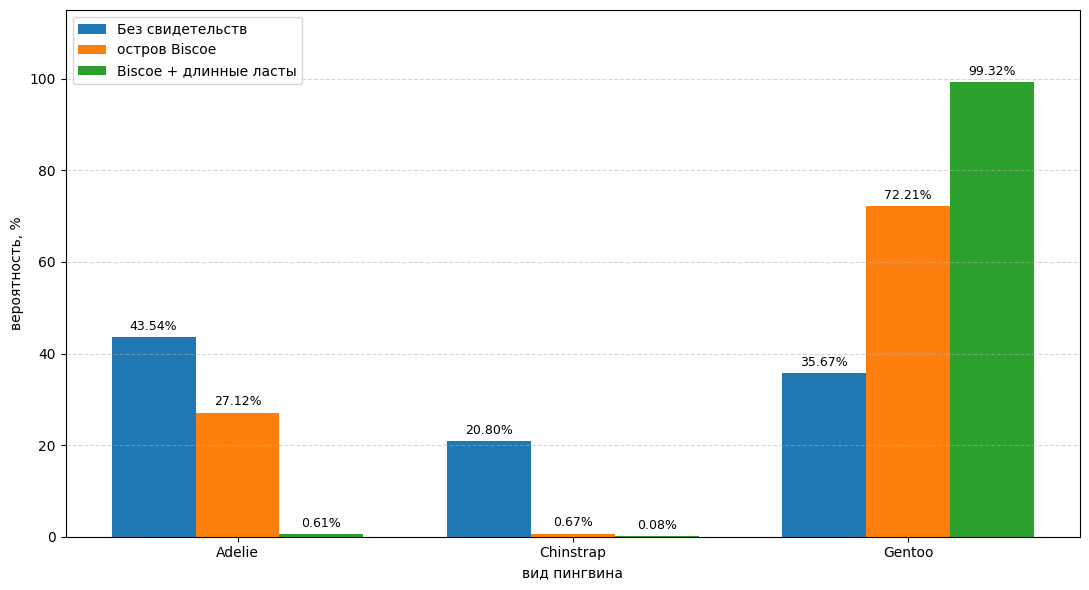

In [ ]:
species = ['Adelie', 'Chinstrap', 'Gentoo']

without_evidence = [43.54, 20.80, 35.67]
biscoe = [27.12, 0.67, 72.21]
biscoe_and_flippers = [0.61, 0.08, 99.32]

x = np.arange(len(species))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width,
    without_evidence,
    width,
    label='Без свидетельств'
)

bars2 = ax.bar(
    x,
    biscoe,
    width,
    label='остров Biscoe'
)

bars3 = ax.bar(
    x + width,
    biscoe_and_flippers,
    width,
    label='Biscoe + длинные ласты'
)

for bars in [bars1, bars2, bars3]:
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=9)

ax.set_xlabel('вид пингвина')
ax.set_ylabel('вероятность, %')

ax.set_xticks(x)
ax.set_xticklabels(species)

ax.set_ylim(0, 115)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

#анализ структуры

In [ ]:
for edge in model.edges():
    print(edge)

('island', 'species')
('species', 'bill_length_mm')
('species', 'flipper_length_mm')
('species', 'sex')
('species', 'body_mass_g')
('sex', 'body_mass_g')


In [ ]:
edges_without_sex = [
    ('island', 'species'),
    ('species', 'bill_length_mm'),
    ('species', 'flipper_length_mm'),
    ('species', 'sex'),
    ('species', 'body_mass_g')
]

model_without_edge = DiscreteBayesianNetwork(edges_without_sex)

model_without_edge.fit(
    discrete_data,
    estimator=DiscreteBayesianEstimator(
        prior_type='BDeu',
        equivalent_sample_size=10
    )
)

model_without_edge.check_model()

True

In [ ]:
len(model_without_edge.edges())

5

In [ ]:
infer_original = VariableElimination(model)

result_original = infer_original.query(
    variables=['body_mass_g'],
    evidence={
        'species': 'Gentoo',
        'sex': 'male'
    },
    show_progress=False
)

infer_modified = VariableElimination(model_without_edge)

result_modified = infer_modified.query(
    variables=['body_mass_g'],
    evidence={
        'species': 'Gentoo',
        'sex': 'male'
    },
    show_progress=False
)

print(result_original)

print("\nбез ребра sex -> body_mass_g:")
print(result_modified)

+---------------------+--------------------+
| body_mass_g         |   phi(body_mass_g) |
+=====================+====================+
| body_mass_g(high)   |             0.9823 |
+---------------------+--------------------+
| body_mass_g(low)    |             0.0089 |
+---------------------+--------------------+
| body_mass_g(medium) |             0.0089 |
+---------------------+--------------------+

без ребра sex -> body_mass_g:
+---------------------+--------------------+
| body_mass_g         |   phi(body_mass_g) |
+=====================+====================+
| body_mass_g(high)   |             0.8429 |
+---------------------+--------------------+
| body_mass_g(low)    |             0.0091 |
+---------------------+--------------------+
| body_mass_g(medium) |             0.1480 |
+---------------------+--------------------+


In [ ]:
result_modified_species_only = infer_modified.query(
    variables=['body_mass_g'],
    evidence={'species': 'Gentoo'},
    show_progress=False
)

print(result_modified_species_only)

+---------------------+--------------------+
| body_mass_g         |   phi(body_mass_g) |
+=====================+====================+
| body_mass_g(high)   |             0.8429 |
+---------------------+--------------------+
| body_mass_g(low)    |             0.0091 |
+---------------------+--------------------+
| body_mass_g(medium) |             0.1480 |
+---------------------+--------------------+
